In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
stu=pd.read_csv("1781453184505-student_dataset_10000_rows.csv")
stu.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


In [3]:
stu.shape

(10000, 8)

In [4]:
stu.describe()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,5.989600,69.88460,6.498500,6.062600,9.988400,64.91100,86.704207
std,3.163589,17.61653,1.709354,3.138163,6.034145,17.50302,15.058383
min,1.000000,40.00000,4.000000,1.000000,0.000000,35.00000,26.670000
25%,3.000000,55.00000,5.000000,3.000000,5.000000,50.00000,76.727500
50%,6.000000,70.00000,6.500000,6.000000,10.000000,65.00000,92.120000
75%,9.000000,85.00000,8.000000,9.000000,15.000000,80.00000,100.000000
max,11.000000,100.00000,9.000000,11.000000,20.000000,95.00000,100.000000


In [5]:
stu.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  object 
dtypes: float64(1), int64(6), object(1)
memory usage: 625.1+ KB


In [6]:
stu.isnull().sum()

study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0
dtype: int64

In [7]:
corr=stu[["study_hours","attendance","sleep_hours","internet_usage",
          "assignments_completed","previous_score","exam_score"]].corr()
corr

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
study_hours,1.000000,0.003801,-0.005255,0.006684,-0.000425,0.009451,0.562528
attendance,0.003801,1.000000,-0.003981,-0.014539,-0.012892,0.001588,0.223367
sleep_hours,-0.005255,-0.003981,1.000000,-0.000038,-0.008234,0.023916,0.144675
internet_usage,0.006684,-0.014539,-0.000038,1.000000,0.020536,0.005371,-0.151896
assignments_completed,-0.000425,-0.012892,-0.008234,0.020536,1.000000,0.004178,0.387609
previous_score,0.009451,0.001588,0.023916,0.005371,0.004178,1.000000,0.318805
exam_score,0.562528,0.223367,0.144675,-0.151896,0.387609,0.318805,1.000000


<Axes: >

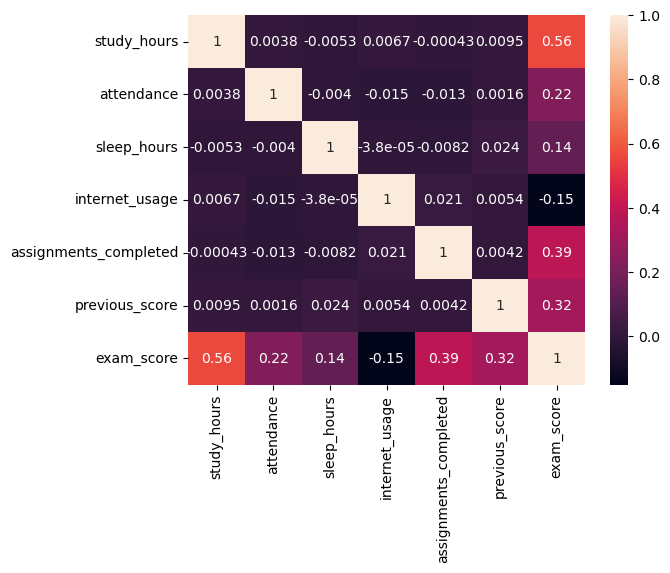

In [9]:

sns.heatmap (corr,annot=True)

In [10]:
# histograms for all numerical feautures
numeric_cols=["study_hours","attendance","sleep_hours","internet_usage",
          "assignments_completed","previous_score","exam_score"]

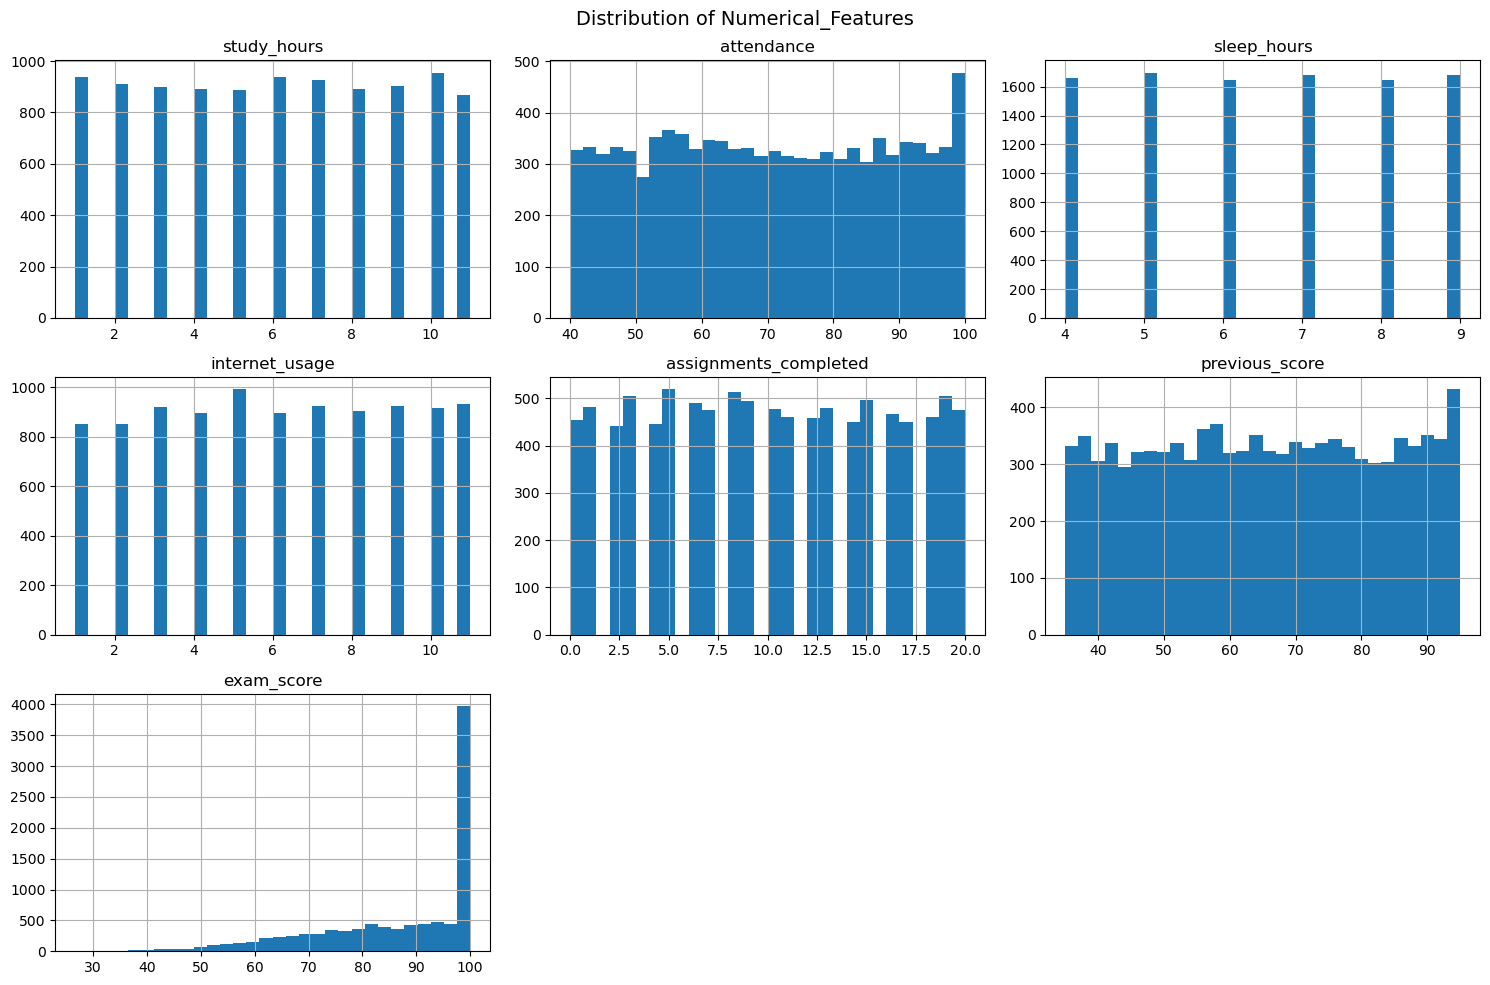

In [11]:
stu[numeric_cols].hist(bins=30,figsize=(15,10),layout=(3,3))
plt.suptitle("Distribution of Numerical_Features",fontsize=14)
plt.tight_layout()
plt.show()

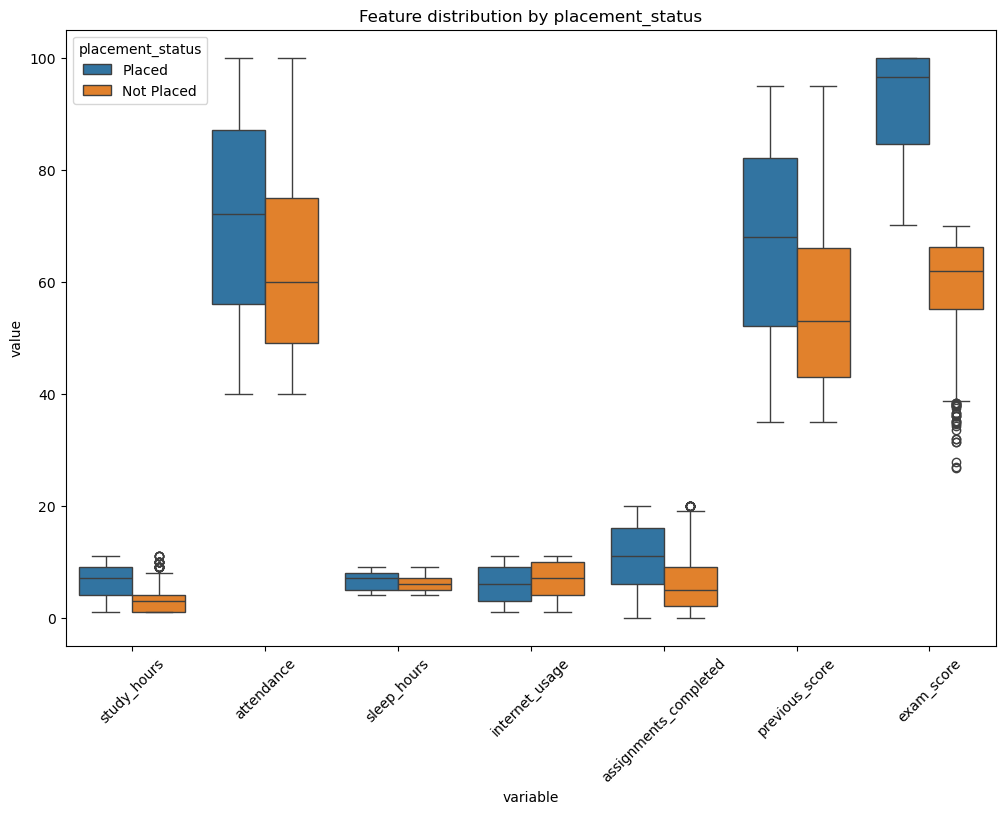

In [12]:
# box plot by payment status to seee what seperates placed vs not placed 
plt.figure(figsize=(12,8))
sns.boxplot(data=stu.melt(id_vars="placement_status",value_vars=numeric_cols),
            x="variable",y="value",hue="placement_status")
plt.xticks(rotation=45)
plt.title("Feature distribution by placement_status")
plt.show()

<Axes: xlabel='exam_score', ylabel='previous_score'>

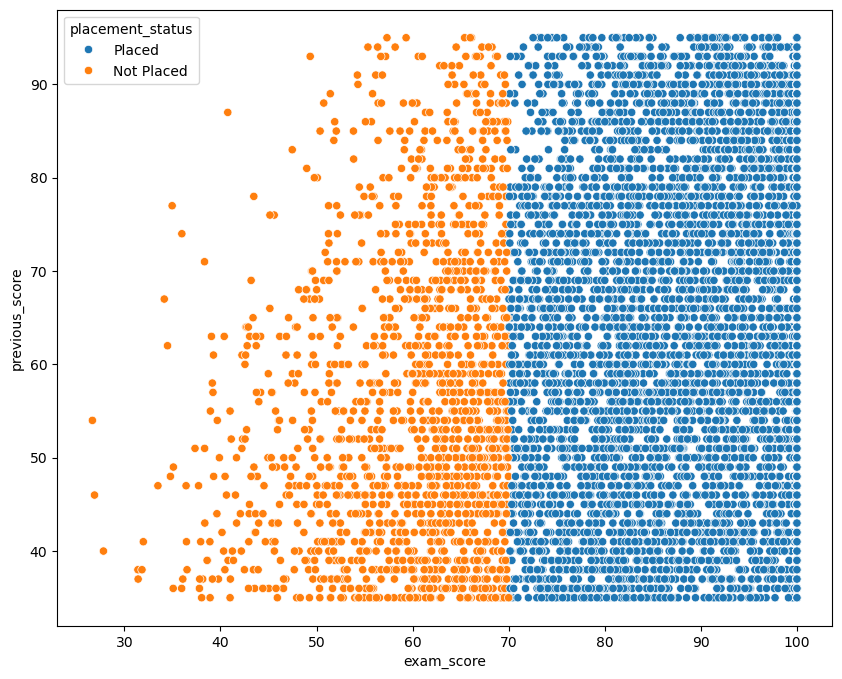

In [13]:
# scatter plot for exam score vs previous score  coloured with placement status
plt.figure(figsize=(10,8))
sns.scatterplot(data=stu,x="exam_score",y="previous_score",hue="placement_status")

In [14]:
# preparing the data 
x=stu[["study_hours","attendance","sleep_hours","internet_usage",
          "assignments_completed","previous_score","exam_score"]]

In [16]:
from sklearn.preprocessing import LabelEncoder
lb=LabelEncoder()
y=lb.fit_transform(stu["placement_status"])
y

array([1, 1, 1, ..., 1, 1, 1], shape=(10000,))

In [17]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [18]:
# shape of training and testing
print("x_train:",x_train.shape,"y_train:",y_train.shape)
print("x_test:",x_test.shape,"y_test:",y_test.shape)

x_train: (8000, 7) y_train: (8000,)
x_test: (2000, 7) y_test: (2000,)


In [20]:
# using standardscalar for preprocessing numerical features
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.fit_transform(x_test)

In [21]:
from sklearn.linear_model import LogisticRegression
model_log=LogisticRegression()
model_log.fit(x_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [22]:
y_pred_log=model_log.predict(x_test_scaled)
y_pred_log  

array([1, 1, 1, ..., 1, 0, 1], shape=(2000,))

In [23]:
y_pred_proba_log=model_log.predict_proba(x_test_scaled)[:,1]
y_pred_proba_log

array([1.00000000e+00, 9.99999112e-01, 9.97136211e-01, ...,
       9.99999999e-01, 2.14938294e-08, 1.00000000e+00], shape=(2000,))

In [24]:
from sklearn.metrics import confusion_matrix,roc_curve,auc

In [25]:
cm=confusion_matrix(y_test,y_pred_log)
cm 

array([[ 327,    2],
       [   3, 1668]])

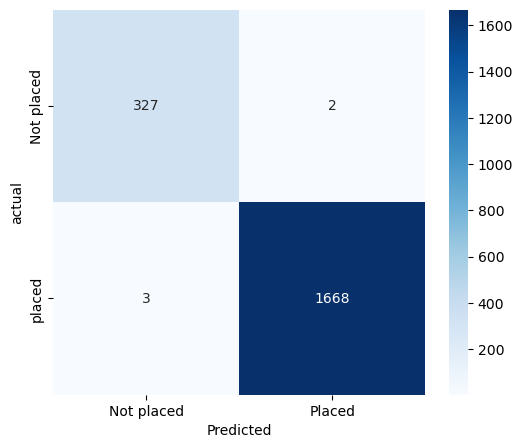

In [26]:
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Not placed","Placed"],yticklabels=["Not placed","placed"])
plt.xlabel("Predicted")
plt.ylabel("actual")
plt.show()

In [27]:
fpr,tpr,thresholds=roc_curve(y_test,y_pred_proba_log)
roc_auc=auc(fpr,tpr)

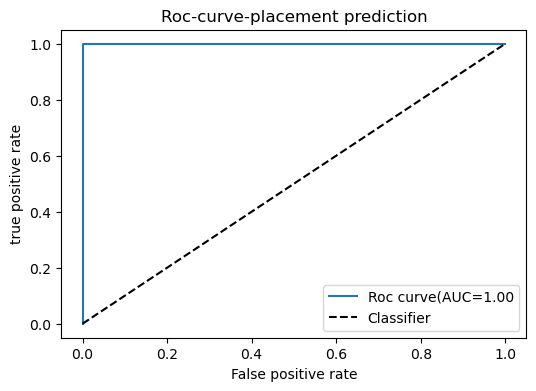

In [28]:
plt.figure(figsize=(6,4))
plt.plot(fpr,tpr,label=f"Roc curve(AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'k--',label="Classifier")
plt.xlabel("False positive rate")
plt.ylabel("true positive rate")
plt.title("Roc-curve-placement prediction")
plt.legend()

In [29]:
from sklearn.metrics import accuracy_score
Accuracy=accuracy_score(y_test,y_pred_log)
print(f"Accuracy:{Accuracy:.2f}")
print(f"Accuracy:{Accuracy*100:.1f}%")

Accuracy:1.00
Accuracy:99.8%


In [30]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_log,target_names=["Not placed","Placed"]))

              precision    recall  f1-score   support

  Not placed       0.99      0.99      0.99       329
      Placed       1.00      1.00      1.00      1671

    accuracy                           1.00      2000
   macro avg       0.99      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

